# 05 · La historia de Jardine: con balón y sin balón

**Qué responde** (todo.md §3.2 y §3.3): cómo sale, por dónde progresa y cómo genera ocasiones el América de
André Jardine; y dónde y cómo recupera el balón, cuánto presiona y cómo le va en las transiciones. Siempre
**frente a Solari y Ortiz** (el "antes") y, donde existe la métrica para toda la liga, **frente a la Liga MX**.

**Reglas del notebook**
- **Muestra**: toda cifra sale de la **ventana oficial (Apertura 2021 – Clausura 2025)**: Jardine 91 partidos,
  Ortiz 55, Solari 27. Validación (Ap 2025) y prueba (2026) no entran aquí.
- **Definiciones**: posesión, transición, recuperación, pase progresivo, zonas y umbrales vienen de `src/framework.py`
  (`ASSUMPTIONS`); este notebook no redefine nada. Los cálculos viven en `src/story.py` y las canchas en
  `src/story_viz.py`, que también consumirá el reporte HTML.
- **Datos**: los eventos solo se usan en memoria. A disco van **solo agregados** (`data/gold/analysis/story_*.parquet`)
  y figuras (`reports/figures/story/`).
- **Cancha**: 120 × 80 yardas, el América ataca hacia la derecha y su banda izquierda queda arriba.

Cada bloque cierra con **una pregunta de fútbol, un hallazgo con número y 1–2 canchas**.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src import story as S, story_viz as V
from src.pipeline.config import GOLD

pd.set_option("display.max_columns", 30, "display.width", 250, "display.float_format", lambda v: f"{v:,.2f}")
FIG = ROOT / "reports" / "figures" / "story"; FIG.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=140, bbox_inches="tight"); plt.show()

H = []  # hallazgos del notebook: bloque, pregunta, hallazgo, figuras (se guardan al final)
def finding(bloque, pregunta, texto, figuras):
    H.append({"bloque": bloque, "pregunta": pregunta, "hallazgo": texto, "figuras": ", ".join(figuras)})
    display(Markdown(f"**{pregunta}**\n\n**Hallazgo.** {texto}"))

dim = pd.read_parquet(GOLD / "dim_match.parquet")
scope = S.match_scope(dim)                  # ventana oficial · Solari / Ortiz / Jardine
ev = S.load_story_events(scope)             # eventos: SOLO en memoria
poss = S.load_possessions(scope)            # fct_possession (Gold)
mf = pd.read_parquet(GOLD / "match_features.parquet")
tml = pd.read_parquet(GOLD / "fct_team_match_league.parquet")
assert set(scope.split) == {"train"}
S.n_matches(scope).to_frame().T

coach,Solari,Ortiz,Jardine
partidos,27,55,91


## 3.2 Con balón

### a) ¿Cómo sale desde atrás?

Se miran los **saques de meta** y los **pases del portero en juego**. *Corto* = menos de 32 yardas (umbral del marco,
`long_pass_yd`). Para cada salida: dónde cae el balón (tercio × carril), quién lo recibe (línea del receptor, si el pase
llega) y qué pasa después con la jugada (¿llega a campo rival? ¿termina en tiro?).

In [2]:
r = S.restarts(ev)                                   # en memoria
rs = S.restart_summary(r, scope)
ro = S.restart_outcomes(r, poss)
rr = S.restart_receivers(r)
zones = S.zone_grid(r, "pass_end_location_x", "pass_end_location_y", ["coach", "kind"])
display(rs, ro)
display((rr[rr.length == "Corto"].pivot_table(index=["kind", "receiver_group"], columns="coach", values="share") * 100)
        .round(0)[S.COACHES])
for df, name in [(rs, "salida_resumen"), (ro, "salida_resultado"), (rr, "salida_receptor"), (zones, "salida_zonas")]:
    S.save_story(df, name)

,coach,kind,n,pct_corto,pct_completo_corto,pct_completo_largo,por_partido
0,Jardine,Portero en juego,1970,53.76,99.06,56.86,21.65
1,Jardine,Saque de meta,759,45.45,100.00,49.76,8.34
2,Ortiz,Portero en juego,1048,51.53,98.52,50.00,19.05
3,Ortiz,Saque de meta,425,31.29,100.00,46.23,7.73
4,Solari,Portero en juego,610,51.48,99.04,54.73,22.59
5,Solari,Saque de meta,208,33.17,100.00,45.32,7.70


,coach,kind,length,n,pct_llega_campo_rival,pct_tiro,xg_por_100
0,Jardine,Portero en juego,Corto,1059,79.60,9.35,1.25
1,Jardine,Portero en juego,Largo,911,73.77,7.90,0.92
2,Jardine,Saque de meta,Corto,345,65.51,5.80,0.72
3,Jardine,Saque de meta,Largo,414,73.91,5.31,0.68
4,Ortiz,Portero en juego,Corto,540,85.93,13.15,1.96
5,Ortiz,Portero en juego,Largo,508,78.94,9.06,1.10
6,Ortiz,Saque de meta,Corto,133,77.44,11.28,2.04
7,Ortiz,Saque de meta,Largo,292,80.14,4.11,0.56
8,Solari,Portero en juego,Corto,314,83.76,7.96,0.58
9,Solari,Portero en juego,Largo,296,83.78,7.77,0.78


coach                             Solari  Ortiz  Jardine
kind             receiver_group                         
Portero en juego Banda              2.00   2.00     2.00
                 Carrilero           NaN    NaN     1.00
                 Defensa           86.00  76.00    77.00
                 Delantero          1.00   0.00     1.00
                 Medio              1.00   1.00     2.00
                 Medio defensivo   10.00  21.00    17.00
                 Medio ofensivo     1.00   1.00     1.00
Saque de meta    Banda              1.00    NaN     2.00
                 Carrilero           NaN    NaN     0.00
                 Defensa           93.00  75.00    44.00
                 Delantero          1.00    NaN     1.00
                 Medio               NaN    NaN     1.00
                 Medio defensivo    4.00  20.00    44.00
                 Medio ofensivo      NaN   1.00     0.00
                 Portero             NaN   5.00     8.00

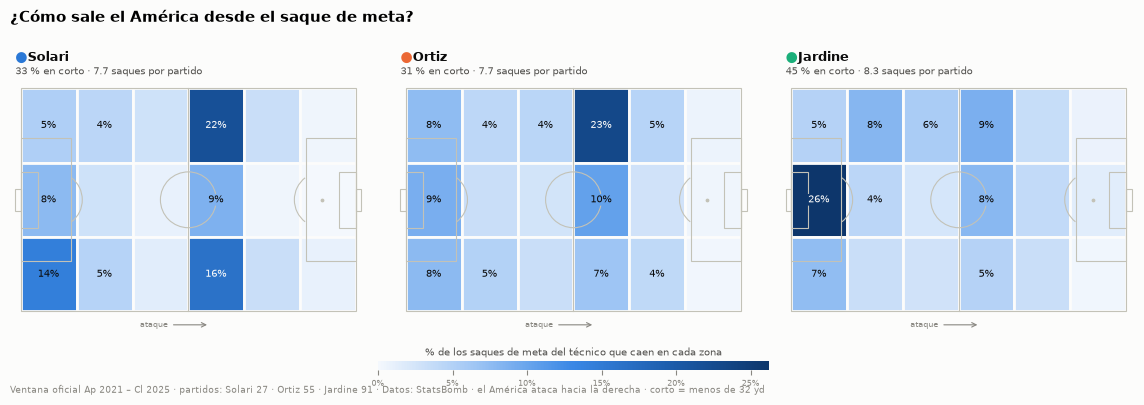

In [3]:
save(V.fig_goal_kicks(zones[zones.kind == "Saque de meta"], rs, scope,
                      "¿Cómo sale el América desde el saque de meta?"), "salida_saque_meta")

In [4]:
gk = rs[rs.kind == "Saque de meta"].set_index("coach")
kp = rs[rs.kind == "Portero en juego"].set_index("coach")
rec = (rr[(rr.kind == "Saque de meta") & (rr.length == "Corto")]
       .pivot(index="receiver_group", columns="coach", values="share").fillna(0) * 100)
out = ro[ro.kind == "Saque de meta"].set_index(["coach", "length"])
finding("3.2a Salida", "¿Cómo sale el América desde atrás?",
    f"Con Jardine el América sale jugando: saca en corto el {gk.loc['Jardine', 'pct_corto']:.0f} % de sus saques de meta, "
    f"frente a {gk.loc['Ortiz', 'pct_corto']:.0f} % con Ortiz y {gk.loc['Solari', 'pct_corto']:.0f} % con Solari. "
    f"Ese pase corto lo recibe un mediocentro que baja a pedirla en el {rec.loc['Medio defensivo', 'Jardine']:.0f} % de los casos "
    f"(Ortiz {rec.loc['Medio defensivo', 'Ortiz']:.0f} %, Solari {rec.loc['Medio defensivo', 'Solari']:.0f} %, que se la daban "
    f"casi siempre a un central). Es una idea de control, no un atajo al gol: "
    f"{out.loc[('Jardine', 'Corto'), 'pct_llega_campo_rival']:.0f} % de esas salidas cortas llega a campo rival "
    f"(Ortiz {out.loc[('Ortiz', 'Corto'), 'pct_llega_campo_rival']:.0f} %; en largo, "
    f"{out.loc[('Jardine', 'Largo'), 'pct_llega_campo_rival']:.0f} %) y generan "
    f"{out.loc[('Jardine', 'Corto'), 'xg_por_100']:.1f} xG por cada 100 salidas, "
    + ("lo mismo que en largo." if round(out.loc[('Jardine', 'Corto'), 'xg_por_100'], 1) == round(out.loc[('Jardine', 'Largo'), 'xg_por_100'], 1)
       else f"frente a {out.loc[('Jardine', 'Largo'), 'xg_por_100']:.1f} en largo."),
    ["salida_saque_meta.png"])

**¿Cómo sale el América desde atrás?**

**Hallazgo.** Con Jardine el América sale jugando: saca en corto el 45 % de sus saques de meta, frente a 31 % con Ortiz y 33 % con Solari. Ese pase corto lo recibe un mediocentro que baja a pedirla en el 44 % de los casos (Ortiz 20 %, Solari 4 %, que se la daban casi siempre a un central). Es una idea de control, no un atajo al gol: 66 % de esas salidas cortas llega a campo rival (Ortiz 77 %; en largo, 74 %) y generan 0.7 xG por cada 100 salidas, lo mismo que en largo.

### b) ¿Por dónde progresa?

**Acciones progresivas** (marco): pases completos y conducciones que acercan el balón al menos 25 % a la portería rival y
terminan en x ≥ 48. Se cuentan por el **carril donde terminan** (izquierdo, central, derecho: tercios del ancho).
**Entradas**: pases completos de juego abierto o conducciones que cruzan al último tercio (x < 80 → x ≥ 80) o que
entran al área desde fuera.

In [5]:
pa = S.progressive_actions(ev)                      # en memoria
prog = S.progression_by_lane(pa, scope)
en = S.entries(ev)                                  # en memoria
ents = S.entry_summary(en, scope)
box_grid = S.grid_per_match(S.zone_grid(en[en.box], "ex", "ey", ["coach"], x_bins=[102, 108, 114, 120],
                                        y_bins=[18, 30, 50, 62.01]), scope)
display((prog.pivot_table(index=["action", "lane"], columns="coach", values="share") * 100).round(0)[S.COACHES])
display(ents.pivot_table(index=["entrada", "lane"], columns="coach", values="por_partido", aggfunc="sum")[S.COACHES])
display(ents.pivot_table(index=["entrada", "method"], columns="coach", values="por_partido", aggfunc="sum")[S.COACHES])
for df, name in [(prog, "progresion_carril"), (ents, "entradas"), (box_grid, "entradas_area_zonas")]:
    S.save_story(df, name)

coach                            Solari  Ortiz  Jardine
action                lane                             
Conducción progresiva Central     23.00  35.00    31.00
                      Derecho     30.00  24.00    31.00
                      Izquierdo   47.00  40.00    38.00
Pase progresivo       Central     36.00  46.00    42.00
                      Derecho     35.00  25.00    26.00
                      Izquierdo   28.00  29.00    32.00

coach                    Solari  Ortiz  Jardine
entrada       lane                             
Área          Central      4.78   6.42     5.92
              Derecho      2.00   3.55     3.82
              Izquierdo    3.15   5.05     4.93
Último tercio Central      5.67  11.73     9.25
              Derecho     14.85  17.05    17.90
              Izquierdo   16.81  20.47    21.05

coach                     Solari  Ortiz  Jardine
entrada       method                            
Área          Centro        2.93   2.78     2.12
              Conducción    3.56   5.78     5.96
              Pase          3.44   6.45     6.60
Último tercio Conducción   14.70  17.98    18.44
              Pase         22.63  31.27    29.77

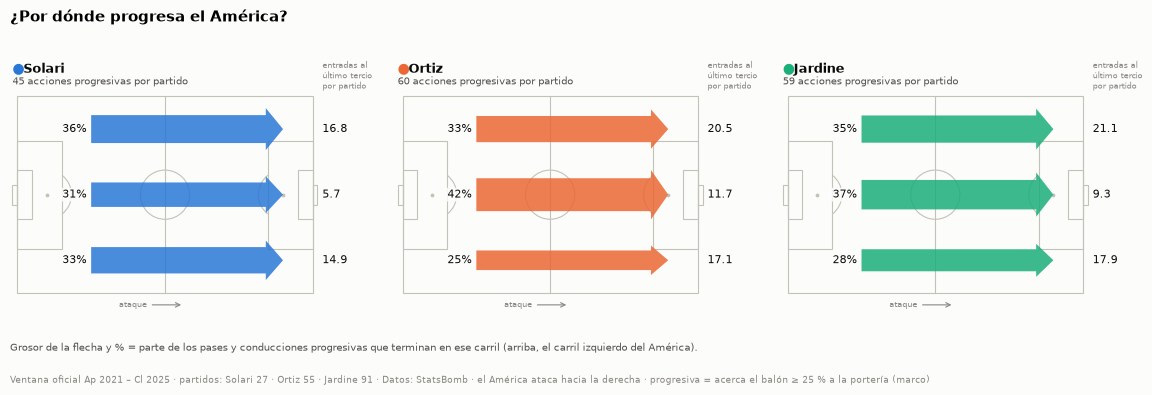

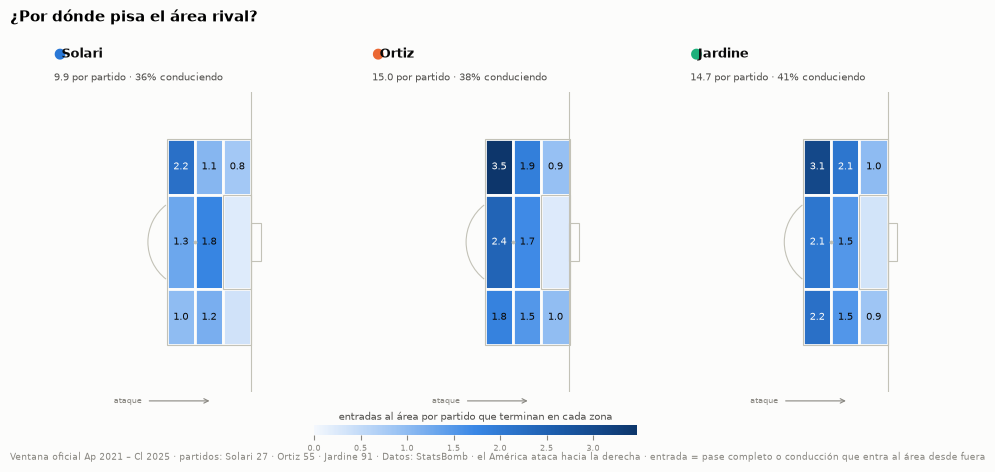

In [6]:
save(V.fig_lanes(prog, ents, scope, "¿Por dónde progresa el América?"), "progresion_carriles")
save(V.fig_box_entries(box_grid, ents, scope, "¿Por dónde pisa el área rival?"), "entradas_area")

In [7]:
pp = prog[prog.action == "Pase progresivo"].set_index(["coach", "lane"]).share * 100
f3 = ents[ents.entrada == "Último tercio"].groupby(["coach", "lane"]).por_partido.sum()
bx = ents[ents.entrada == "Área"].groupby("coach").por_partido.sum()
bxc = ents[(ents.entrada == "Área") & (ents.method == "Conducción")].groupby("coach").por_partido.sum() / bx * 100
finding("3.2b Progresión", "¿Por dónde progresa el América?",
    f"Jardine progresa por dentro y entra por fuera. El {pp['Jardine', 'Central']:.0f} % de sus pases progresivos termina en el "
    f"carril central, pero al último tercio llega sobre todo por las bandas: {f3['Jardine', 'Izquierdo']:.1f} entradas por "
    f"partido por la izquierda y {f3['Jardine', 'Derecho']:.1f} por la derecha, frente a {f3['Jardine', 'Central']:.1f} por el centro. "
    f"Pisa el área {bx['Jardine']:.1f} veces por partido, como Ortiz ({bx['Ortiz']:.1f}) y {(bx['Jardine'] / bx['Solari'] - 1) * 100:.0f} % "
    f"más que Solari ({bx['Solari']:.1f}); {bxc['Jardine']:.0f} % de esas entradas son conduciendo "
    f"(Ortiz {bxc['Ortiz']:.0f} %, Solari {bxc['Solari']:.0f} %).",
    ["progresion_carriles.png", "entradas_area.png"])

**¿Por dónde progresa el América?**

**Hallazgo.** Jardine progresa por dentro y entra por fuera. El 42 % de sus pases progresivos termina en el carril central, pero al último tercio llega sobre todo por las bandas: 21.1 entradas por partido por la izquierda y 17.9 por la derecha, frente a 9.3 por el centro. Pisa el área 14.7 veces por partido, como Ortiz (15.0) y 48 % más que Solari (9.9); 41 % de esas entradas son conduciendo (Ortiz 38 %, Solari 36 %).

### c) ¿Cómo genera ocasiones?

Tiros **sin penales**. **Origen** (definiciones del marco, las mismas de `xg_share_*` en `src/features.py`):
*balón parado* = la posesión nace de un córner o un tiro libre (o de un saque de banda en el último tercio), sea cual sea
la jugada que siga; *transición* = posesión que nace de un robo y llega al último tercio o al tiro en ≤ 15 s; *juego
posicional* = todo lo demás. **Jugada previa al tiro**: tiro libre directo → servicio a balón parado → pase atrás al área
(bandera de StatsBomb o pase raso desde la línea del área hacia atrás, a la zona de peligro) → centro → filtrado → otro pase
→ jugada individual (sin pase clave, tras regate o conducción propia ≥ 5 yd) → rebote o balón suelto.

In [8]:
sh = S.shots(ev, poss)                              # en memoria
tot = S.shot_totals(sh, scope)
org = S.chance_summary(sh, scope, "origin")
ast = S.chance_summary(sh, scope, "assist")
display(tot)
display(org.pivot(index="origin", columns="coach", values=["pct_xg", "xg_por_partido", "xg_por_tiro"]).round(2))
display(ast.pivot(index="assist", columns="coach", values=["pct_xg", "xg_por_tiro"]).reindex(S.ASSISTS).round(2))
for df, name in [(tot, "ocasiones_total"), (org, "ocasiones_origen"), (ast, "ocasiones_pase_previo"),
                 (S.shot_grid(sh), "tiros_rejilla")]:
    S.save_story(df, name)

,coach,tiros,np_xg,goles,pct_tiros_en_area,tiros_por_partido,np_xg_por_partido,xg_por_tiro
0,Solari,335,26.21,26,60.00,12.41,0.97,0.08
1,Ortiz,877,86.30,102,57.58,15.95,1.57,0.10
2,Jardine,1197,137.87,147,65.08,13.15,1.52,0.12


pct_xg              xg_por_partido              xg_por_tiro             
coach            Jardine Ortiz Solari        Jardine Ortiz Solari     Jardine Ortiz Solari
origin                                                                                    
Balón parado       39.96 37.26  45.49           0.61  0.58   0.44        0.11  0.09   0.07
Juego posicional   24.53 30.35  22.56           0.37  0.48   0.22        0.12  0.12   0.09
Transición         35.52 32.39  31.95           0.54  0.51   0.31        0.12  0.09   0.08

pct_xg              xg_por_tiro             
coach                   Jardine Ortiz Solari     Jardine Ortiz Solari
assist                                                               
Centro                    16.68 15.81  28.22        0.17  0.12   0.12
Pase atrás al área        14.78 10.37   8.18        0.14  0.13   0.08
Filtrado                   8.29  8.83   3.13        0.21  0.26   0.16
Otro pase                 28.06 33.38  24.55        0.08  0.08   0.06
Servicio a balón parado    6.81  9.31  13.23        0.09  0.09   0.08
Tiro libre directo         1.15  1.90   2.11        0.04  0.03   0.03
Jugada individual          2.74  5.01   4.38        0.07  0.09   0.06
Rebote o balón suelto     21.48 15.39  16.20        0.16  0.12   0.09

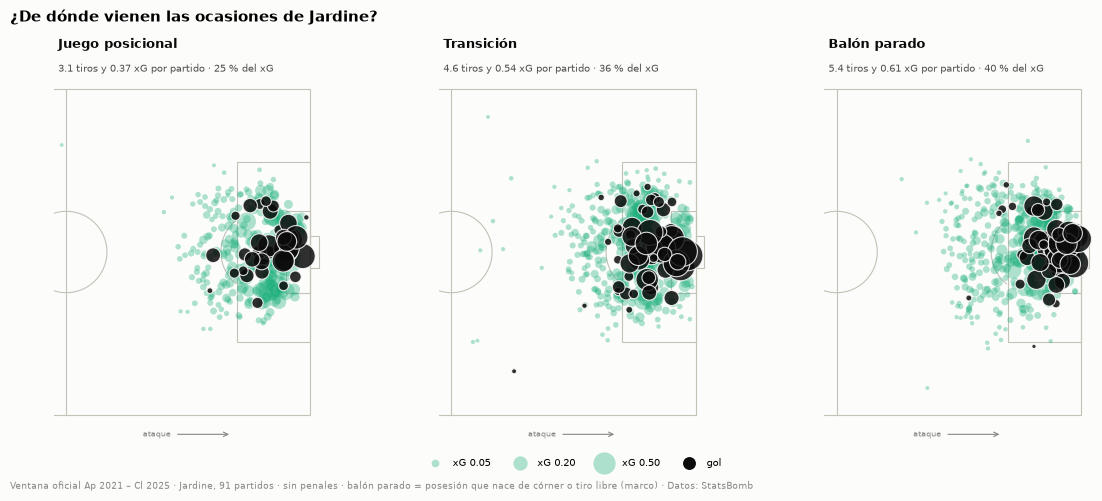

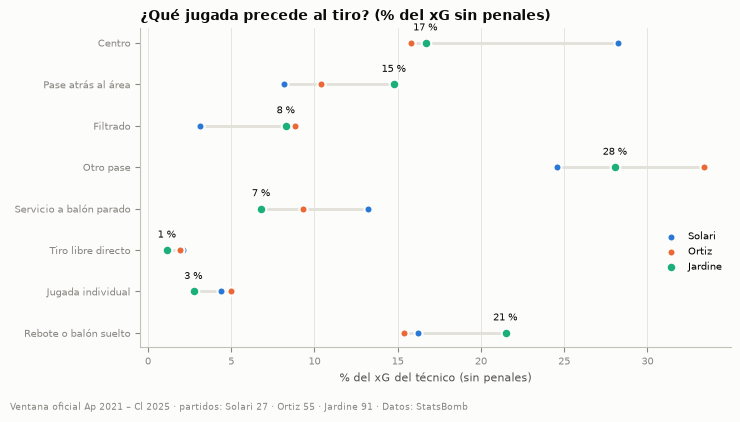

In [9]:
save(V.fig_shot_map(sh, org, scope, "¿De dónde vienen las ocasiones de Jardine?"), "tiros_origen")
save(V.fig_assists(ast, scope, "¿Qué jugada precede al tiro? (% del xG sin penales)", S.ASSISTS), "pase_previo")

In [10]:
t = tot.set_index("coach")
o = org.set_index(["coach", "origin"]).pct_xg
a = ast.pivot(index="assist", columns="coach", values="pct_xg").fillna(0)
finding("3.2c Ocasiones", "¿Cómo genera ocasiones el América?",
    f"Jardine no tira más, tira mejor: {t.loc['Jardine', 'tiros_por_partido']:.1f} tiros y "
    f"{t.loc['Jardine', 'np_xg_por_partido']:.2f} xG por partido sin penales (Ortiz {t.loc['Ortiz', 'tiros_por_partido']:.1f} tiros y "
    f"{t.loc['Ortiz', 'np_xg_por_partido']:.2f} xG), con {t.loc['Jardine', 'xg_por_tiro']:.2f} xG por tiro frente a "
    f"{t.loc['Ortiz', 'xg_por_tiro']:.2f} de Ortiz y {t.loc['Solari', 'xg_por_tiro']:.2f} de Solari, y "
    f"{t.loc['Jardine', 'pct_tiros_en_area']:.0f} % de sus tiros dentro del área. De su xG, "
    f"{o['Jardine', 'Juego posicional']:.0f} % nace del juego posicional, {o['Jardine', 'Transición']:.0f} % de transiciones y "
    f"{o['Jardine', 'Balón parado']:.0f} % de balón parado. Su jugada distintiva es el pase atrás al área: "
    f"{a.loc['Pase atrás al área', 'Jardine']:.0f} % del xG (Ortiz {a.loc['Pase atrás al área', 'Ortiz']:.0f} %, Solari "
    f"{a.loc['Pase atrás al área', 'Solari']:.0f} %); el centro pesa menos que con Solari "
    f"({a.loc['Centro', 'Jardine']:.0f} % frente a {a.loc['Centro', 'Solari']:.0f} %).",
    ["tiros_origen.png", "pase_previo.png"])

**¿Cómo genera ocasiones el América?**

**Hallazgo.** Jardine no tira más, tira mejor: 13.2 tiros y 1.52 xG por partido sin penales (Ortiz 15.9 tiros y 1.57 xG), con 0.12 xG por tiro frente a 0.10 de Ortiz y 0.08 de Solari, y 65 % de sus tiros dentro del área. De su xG, 25 % nace del juego posicional, 36 % de transiciones y 40 % de balón parado. Su jugada distintiva es el pase atrás al área: 15 % del xG (Ortiz 10 %, Solari 8 %); el centro pesa menos que con Solari (17 % frente a 28 %).

### d) ¿Quién conecta con quién?

**El 11 más usado**: el sistema más frecuente de Jardine en la ventana y, en cada puesto, el jugador que más veces lo
ocupó de titular. La red usa solo los partidos con ese sistema, cada jugador en los partidos en que fue titular en su
puesto, y los pases completos de juego abierto **hasta el primer cambio** (para que la foto sea la de ese 11). Nodo =
posición media de sus pases y recepciones; línea = pases entre la pareja por partido que jugaron juntos.

In [11]:
lu = S.starting_lineups(ev)
lj = lu[lu.coach == S.PROTAGONIST]
xi = S.most_used_xi(lj)
nodes, edges = S.pass_network(ev, lj, xi, names=S.player_short_names())
names = nodes.set_index("player_id").nombre
edges = edges.assign(jugador_a=edges.a.map(names), jugador_b=edges.b.map(names))
display(lj.drop_duplicates("match_id").formation.value_counts().head(5).to_frame("partidos"))
display(xi.assign(nombre=xi.player_id.map(names))[["position", "nombre", "titularidades"]])
display(nodes.sort_values("pases_por_partido", ascending=False)[["nombre", "position", "x_media", "y_media", "pases_por_partido", "partidos"]])
display(edges.sort_values("pases_por_partido", ascending=False).head(8)[["jugador_a", "jugador_b", "pases_por_partido", "partidos_juntos"]])
for df, name in [(xi, "red_xi"), (nodes, "red_nodos"), (edges, "red_aristas")]:
    S.save_story(df, name, muestra=f"ventana · {S.PROTAGONIST}")

,partidos
formation,
4231,41
442,23
433,7
343,7
4141,5


,position,nombre,titularidades
0,Goalkeeper,Luis Malagón,35
1,Center Attacking Midfield,Diego Valdés,26
2,Center Forward,Henry Martín,25
3,Right Wing,Alejandro Zendejas,23
4,Left Defensive Midfield,Álvaro Fidalgo,23
5,Right Back,Kevin Álvarez,21
6,Right Defensive Midfield,Jonathan dos Santos,20
7,Left Back,Cristian Calderón,20
8,Right Center Back,Igor Lichnovsky,15
9,Left Center Back,Ramón Juárez,15


,nombre,position,x_media,y_media,pases_por_partido,partidos
10,Álvaro Fidalgo,Left Defensive Midfield,62.30,29.14,28.48,23
0,Jonathan dos Santos,Right Defensive Midfield,57.85,43.65,27.10,20
1,Igor Lichnovsky,Right Center Back,42.35,57.18,14.73,15
9,Ramón Juárez,Left Center Back,36.48,27.43,13.40,15
5,Alejandro Zendejas,Right Wing,76.73,56.71,12.91,23
3,Diego Valdés,Center Attacking Midfield,74.78,37.01,11.38,26
2,Cristian Calderón,Left Back,60.35,11.16,10.55,20
6,Kevin Álvarez,Right Back,70.70,68.61,10.33,21
7,Brian Rodríguez,Left Wing,79.43,12.10,7.00,14
4,Henry Martín,Center Forward,78.57,38.88,5.52,25


,jugador_a,jugador_b,pases_por_partido,partidos_juntos
9,Jonathan dos Santos,Álvaro Fidalgo,21.11,19
50,Brian Rodríguez,Álvaro Fidalgo,15.50,4
25,Cristian Calderón,Álvaro Fidalgo,12.18,11
14,Igor Lichnovsky,Kevin Álvarez,10.40,5
16,Igor Lichnovsky,Ramón Juárez,10.11,9
4,Jonathan dos Santos,Alejandro Zendejas,10.07,14
39,Alejandro Zendejas,Kevin Álvarez,9.23,13
0,Jonathan dos Santos,Igor Lichnovsky,9.20,10


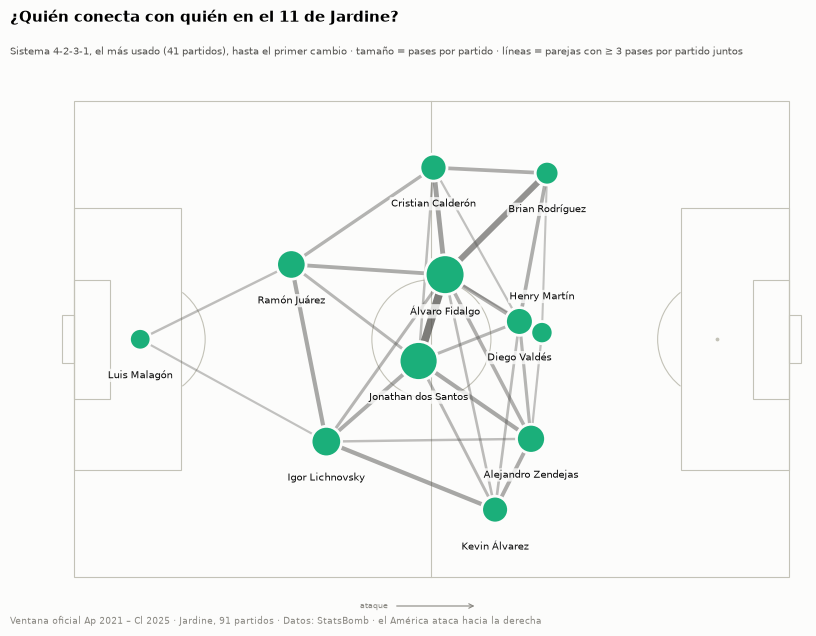

In [12]:
save(V.fig_pass_network(nodes, edges, xi, "¿Quién conecta con quién en el 11 de Jardine?",
                        f"Ventana oficial Ap 2021 – Cl 2025 · Jardine, {int((scope.coach == 'Jardine').sum())} partidos · "
                        "Datos: StatsBomb · el América ataca hacia la derecha"),
     "red_pases")

In [13]:
nd = nodes.sort_values("pases_por_partido", ascending=False)
e = edges[edges.partidos_juntos >= 5].sort_values("pases_por_partido", ascending=False)
top3 = "; ".join(f"{r.jugador_a}–{r.jugador_b} ({r.pases_por_partido:.0f})" for r in e.head(3).itertuples())
left = nodes[nodes.y_media < 40].pases_por_partido.sum() / nodes.pases_por_partido.sum() * 100
finding("3.2d Red de pases", "¿Quién conecta con quién en el 11 de Jardine?",
    f"En el {'-'.join(xi.formation.iat[0])} más usado ({xi.partidos_sistema.iat[0]} de {int((scope.coach == 'Jardine').sum())} partidos), "
    f"el balón pasa por el doble pivote: {nd.nombre.iat[0]} ({nd.pases_por_partido.iat[0]:.0f} pases por partido) y "
    f"{nd.nombre.iat[1]} ({nd.pases_por_partido.iat[1]:.0f}) son los que más pases dan. Las conexiones más usadas "
    f"(pases por partido juntos) son {top3}. El juego se carga a la izquierda: los jugadores de ese lado "
    f"dan {left:.0f} % de los pases del 11.",
    ["red_pases.png"])

**¿Quién conecta con quién en el 11 de Jardine?**

**Hallazgo.** En el 4-2-3-1 más usado (41 de 91 partidos), el balón pasa por el doble pivote: Álvaro Fidalgo (28 pases por partido) y Jonathan dos Santos (27) son los que más pases dan. Las conexiones más usadas (pases por partido juntos) son Jonathan dos Santos–Álvaro Fidalgo (21); Cristian Calderón–Álvaro Fidalgo (12); Igor Lichnovsky–Kevin Álvarez (10). El juego se carga a la izquierda: los jugadores de ese lado dan 56 % de los pases del 11.

## 3.3 Sin balón

### a) ¿Dónde recupera el balón?

**Recuperación** (marco: `regain`) = posesión propia que nace de un robo, una intercepción, un duelo ganado o un
bloqueo. Se ubica donde empieza esa posesión. *Campo rival* = x ≥ 60.

,coach,recuperaciones,altura_media_x,pct_campo_rival,pct_ultimo_tercio,pct_a_transicion,pct_a_tiro,por_partido,por_100_pos_rivales
0,Solari,1376,42.66,23.98,8.28,35.17,9.38,50.96,47.14
1,Ortiz,3009,42.13,24.66,7.94,36.66,12.26,54.71,51.54
2,Jardine,4717,41.76,23.77,8.10,37.67,10.88,51.84,50.11


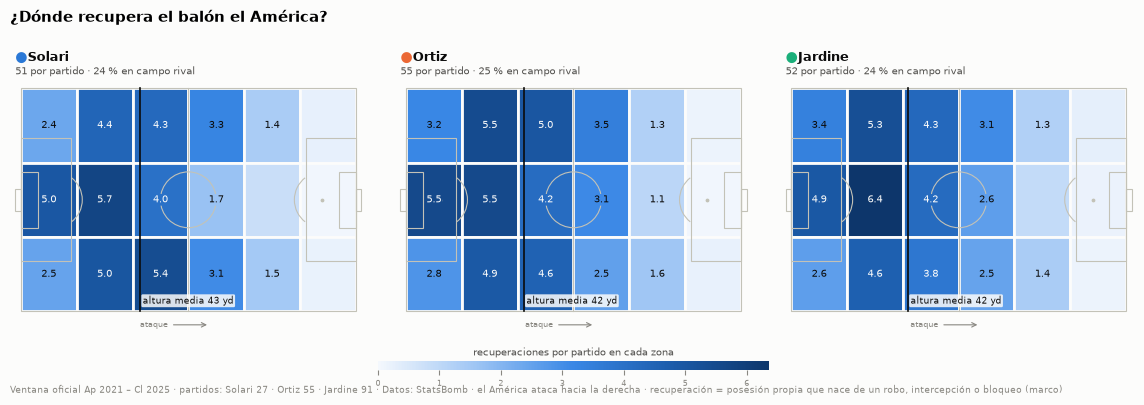

In [14]:
rec = S.recoveries(poss)                            # en memoria
rsum = S.recovery_summary(rec, poss, scope)
rgrid = S.grid_per_match(S.zone_grid(rec, "x", "y", ["coach"]), scope)
display(rsum)
S.save_story(rsum, "recuperaciones"); S.save_story(rgrid, "recuperaciones_zonas")
save(V.fig_recoveries(rgrid, rsum, scope, "¿Dónde recupera el balón el América?"), "recuperaciones")

In [15]:
rm = rsum.set_index("coach")
best = rgrid[rgrid.coach == "Jardine"].sort_values("por_partido").iloc[-1]
finding("3.3a Recuperación", "¿Dónde recupera el balón el América?",
    f"Jardine no roba más arriba que sus antecesores: recupera {rm.loc['Jardine', 'por_partido']:.0f} balones por partido a una "
    f"altura media de {rm.loc['Jardine', 'altura_media_x']:.0f} yd de su portería (Solari {rm.loc['Solari', 'altura_media_x']:.0f}, "
    f"Ortiz {rm.loc['Ortiz', 'altura_media_x']:.0f}) y {rm.loc['Jardine', 'pct_campo_rival']:.0f} % en campo rival "
    f"(Solari {rm.loc['Solari', 'pct_campo_rival']:.0f} %, Ortiz {rm.loc['Ortiz', 'pct_campo_rival']:.0f} %). Su zona de robo es "
    f"el centro de su propio campo, justo delante del área ({best.por_partido:.1f} recuperaciones por partido entre las "
    f"{best.x0:.0f} y las {best.x1:.0f} yd), y {rm.loc['Jardine', 'pct_a_transicion']:.0f} % de lo que recupera se convierte en "
    f"transición (Solari {rm.loc['Solari', 'pct_a_transicion']:.0f} %, Ortiz {rm.loc['Ortiz', 'pct_a_transicion']:.0f} %).",
    ["recuperaciones.png"])

**¿Dónde recupera el balón el América?**

**Hallazgo.** Jardine no roba más arriba que sus antecesores: recupera 52 balones por partido a una altura media de 42 yd de su portería (Solari 43, Ortiz 42) y 24 % en campo rival (Solari 24 %, Ortiz 25 %). Su zona de robo es el centro de su propio campo, justo delante del área (6.4 recuperaciones por partido entre las 20 y las 40 yd), y 38 % de lo que recupera se convierte en transición (Solari 35 %, Ortiz 37 %).

### b) ¿Presiona más o menos que la liga?

Dos fuentes, cada una para lo suyo:
- **Frente a Solari y Ortiz**, con las métricas del marco calculadas con eventos (`match_features`: PPDA, % de acciones
  defensivas en campo rival, contrapresión por pérdida, % de pérdidas recuperadas en ≤ 5 s).
- **Frente a la liga**, con las métricas de StatsBomb que existen para todos los equipos (`fct_team_match_league`), la
  misma fuente para el América y para los 70 técnicos-club con 15 partidos o más en la ventana.

**Ajuste por época.** La liga entera se mueve en la ventana (el PPDA medio pasa de ~8 en 2021 a ~12 en 2024 y las
recuperaciones por contrapresión se duplican desde el Apertura 2024), así que cada partido se compara con la **media de
la liga en el mismo torneo**. Sin ese ajuste, un técnico reciente como Jardine parecería presionar menos solo por la época.

In [16]:
press = S.pressing_by_coach(mf, scope)
bench = S.league_benchmark(tml)                     # diferencia con la liga del mismo torneo
bench_raw = S.league_benchmark(tml, relative=False) # valores crudos (para citar el número absoluto)
ranks = pd.DataFrame([{"metrica": c, "etiqueta": lab, "lectura": better, "coach": co,
                       **S.league_rank(bench, c, co), "valor_crudo": bench_raw.loc[bench_raw.coach == co, c].iat[0]}
                      for c, (lab, better) in S.LEAGUE_METRICS.items() for co in S.COACHES])
display(press[["coach"] + S.PRESS_METRICS])
display(ranks.pivot(index="etiqueta", columns="coach", values=["valor", "percentil"]).round(2))
S.save_story(press, "presion"); S.save_story(bench, "presion_liga"); S.save_story(ranks, "presion_liga_rank")

,coach,ppda,high_press_pct,def_action_x_mean,high_regains_per100opp,counterpress_per_loss,quick_regain_pct
0,Solari,10.23,43.40,54.80,11.01,0.95,13.56
1,Ortiz,11.44,41.60,53.65,12.50,0.95,12.20
2,Jardine,13.83,39.94,52.51,11.76,0.90,13.85


valor              percentil             
coach                                              Jardine Ortiz Solari   Jardine Ortiz Solari
etiqueta                                                                                      
% de presiones en campo rival                         0.02  0.03   0.06     70.71 87.86  97.86
Contrapresiones por partido                          -2.26 -0.10  -3.41     17.86 60.71   9.29
Distancia media de las acciones defensivas a su...    1.10  1.75   2.11     79.29 90.71  93.57
PPDA (pases rivales por acción defensiva)             1.90 -0.55   0.39     85.00 39.29  66.43
Recuperaciones por contrapresión por partido          0.21  0.11  -1.25     73.57 67.86  17.86
Tiros de contraataque concedidos por partido         -0.24 -0.33  -0.48     19.29 10.71   5.00
Tiros de contraataque por partido                     0.08  0.04  -0.52     69.29 60.71   6.43

'C:\\Users\\pauli\\Documents\\ISAC\\ISAC-Hackathon-America\\data\\gold\\analysis\\story_presion_liga_rank.parquet'

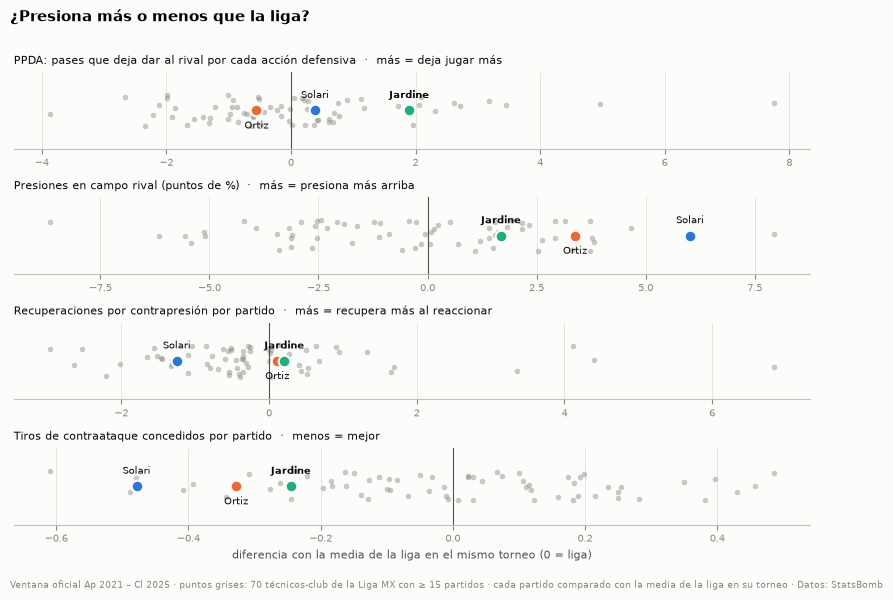

In [17]:
PRESS_FIG = {
    "team_match_ppda": ("PPDA: pases que deja dar al rival por cada acción defensiva", "más = deja jugar más", 1),
    "team_match_fhalf_pressures_ratio": ("Presiones en campo rival (puntos de %)", "más = presiona más arriba", 100),
    "team_match_counterpressure_regains": ("Recuperaciones por contrapresión por partido", "más = recupera más al reaccionar", 1),
    "team_match_counter_attacking_shots_conceded": ("Tiros de contraataque concedidos por partido", "menos = mejor", 1),
}
save(V.fig_press_league(bench, PRESS_FIG, "¿Presiona más o menos que la liga?",
                        "Ventana oficial Ap 2021 – Cl 2025 · puntos grises: 70 técnicos-club de la Liga MX con ≥ 15 partidos · "
                        "cada partido comparado con la media de la liga en su torneo · Datos: StatsBomb"),
     "presion_liga")

In [18]:
rk = ranks.set_index(["metrica", "coach"])
pp_ = rk.loc[("team_match_ppda", "Jardine")]
fh = rk.loc[("team_match_fhalf_pressures_ratio", "Jardine")]
cpr = rk.loc[("team_match_counterpressure_regains", "Jardine")]
cpn = rk.loc[("team_match_counterpressures", "Jardine")]
pm = press.set_index("coach")
finding("3.3b Presión", "¿Presiona más o menos que la liga?",
    f"Jardine no asfixia al rival: le deja dar {abs(pp_.valor):.1f} pases {'más' if pp_.valor > 0 else 'menos'} por cada intento de recuperación que la media de la "
    f"liga en el mismo torneo (PPDA; el {int(pp_.lugar)}.º más alto de {int(pp_.de)} técnicos), mientras Ortiz presionaba más que "
    f"la liga ({rk.loc[('team_match_ppda', 'Ortiz'), 'valor']:+.1f}). Con los eventos se ve igual: PPDA mediano de "
    f"{pm.loc['Jardine', 'ppda']:.1f} frente a {pm.loc['Ortiz', 'ppda']:.1f} de Ortiz y {pm.loc['Solari', 'ppda']:.1f} de Solari. "
    f"Pero cuando presiona, lo hace arriba: {fh.valor * 100:.1f} puntos más de sus presiones en campo rival que la liga "
    f"(más que {fh.percentil:.0f} de cada 100 técnicos), y aunque tras perder el balón contrapresiona menos que la liga "
    f"({abs(cpn.valor):.1f} veces menos por partido), recupera un poco más así ({cpr.valor:.1f} balones más por partido; "
    f"más que {cpr.percentil:.0f} de cada 100 técnicos).",
    ["presion_liga.png"])

**¿Presiona más o menos que la liga?**

**Hallazgo.** Jardine no asfixia al rival: le deja dar 1.9 pases más por cada intento de recuperación que la media de la liga en el mismo torneo (PPDA; el 11.º más alto de 70 técnicos), mientras Ortiz presionaba más que la liga (-0.6). Con los eventos se ve igual: PPDA mediano de 13.8 frente a 11.4 de Ortiz y 10.2 de Solari. Pero cuando presiona, lo hace arriba: 1.7 puntos más de sus presiones en campo rival que la liga (más que 71 de cada 100 técnicos), y aunque tras perder el balón contrapresiona menos que la liga (2.3 veces menos por partido), recupera un poco más así (0.2 balones más por partido; más que 74 de cada 100 técnicos).

### c) ¿Cómo le va en las transiciones?

**Transición ofensiva** (marco): posesión que nace de un robo y llega al último tercio o al tiro en ≤ 15 s (sin balón
parado). **Transición defensiva**: lo mismo, pero del rival. La velocidad es el tiempo (mediana, en segundos) desde el
robo hasta el último tercio o el tiro. En los mapas, todo en coordenadas del América: las transiciones del rival se ubican
**donde el América perdió el balón**. Además, la reacción inmediata tras perder: % de pérdidas recuperadas en ≤ 5 s.

,coach,transiciones,segundos_mediana,pct_tiro,xg,xg_por_transicion,pct_de_recuperaciones,por_partido,xg_por_partido,lado
0,Solari,484,6.00,20.87,8.37,0.02,35.17,17.93,0.31,A favor
1,Ortiz,1103,6.00,24.39,27.96,0.03,36.66,20.05,0.51,A favor
2,Jardine,1777,6.00,21.61,48.97,0.03,37.67,19.53,0.54,A favor
3,Solari,405,6.00,19.51,8.24,0.02,28.85,15.00,0.31,En contra
4,Ortiz,922,6.00,21.04,16.88,0.02,32.98,16.76,0.31,En contra
5,Jardine,1566,5.00,21.14,27.01,0.02,33.96,17.21,0.30,En contra


,coach,losses,quick_regains,pct_recuperado_5s,perdidas_por_partido
0,Solari,1277,195,15.27,47.30
1,Ortiz,2593,348,13.42,47.15
2,Jardine,4337,612,14.11,47.66


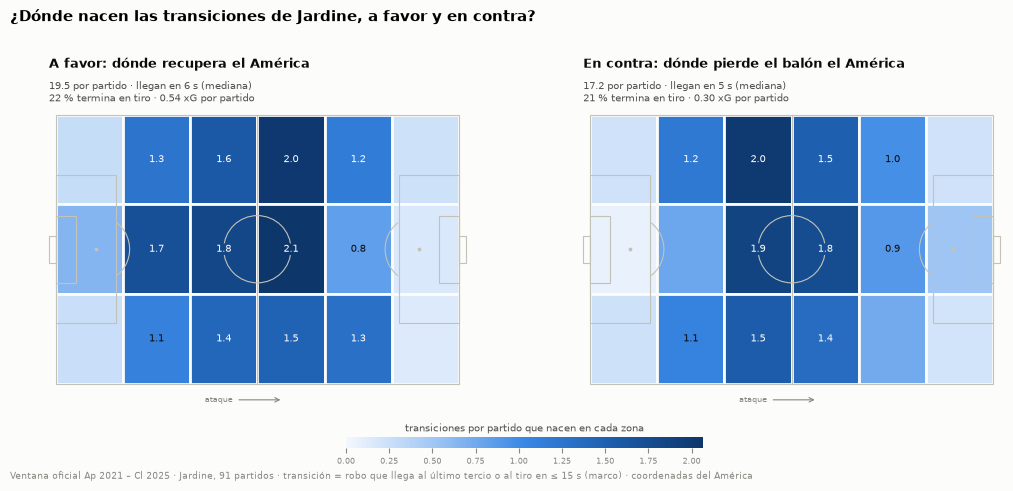

In [19]:
tr = S.transition_summary(poss, scope)
cp = S.counterpress_summary(poss, scope)
starts = S.transition_starts(poss)                  # en memoria
tgrid = S.grid_per_match(S.zone_grid(starts, "x", "y", ["coach", "lado"], ("xg",)), scope)
display(tr, cp)
for df, name in [(tr, "transiciones"), (cp, "contrapresion"), (tgrid, "transiciones_zonas")]:
    S.save_story(df, name)
save(V.fig_transitions(tgrid, tr, scope, "¿Dónde nacen las transiciones de Jardine, a favor y en contra?"), "transiciones")

In [20]:
t = tr.set_index(["coach", "lado"])
ratio = {c: t.loc[(c, "A favor"), "xg_por_partido"] / t.loc[(c, "En contra"), "xg_por_partido"] for c in S.COACHES}
ca = S.league_rank(bench, "team_match_counter_attacking_shots_conceded", "Jardine", higher_is_more=False)
ca_raw = rk.loc[("team_match_counter_attacking_shots_conceded", "Jardine"), "valor_crudo"]
fav, con = t.loc[("Jardine", "A favor")], t.loc[("Jardine", "En contra")]
finding("3.3c Transiciones", "¿Cómo le va al América en las transiciones?",
    f"Jardine gana el intercambio: {fav.por_partido:.1f} transiciones a favor por partido que valen {fav.xg_por_partido:.2f} xG, "
    f"frente a {con.por_partido:.1f} del rival que valen {con.xg_por_partido:.2f} xG: {ratio['Jardine']:.1f} veces más peligro a "
    f"favor que en contra (Ortiz {ratio['Ortiz']:.1f}, Solari {ratio['Solari']:.1f}). Las suyas llegan al último tercio en "
    f"unos {fav.segundos_mediana:.0f} s (las del rival, en {con.segundos_mediana:.0f} s). Frente a la liga concede pocos contragolpes: {ca_raw:.2f} tiros de contraataque por "
    f"partido, {-ca['valor']:.2f} menos que la media de su torneo ({ca['lugar']}.º que menos de {ca['de']} técnicos).",
    ["transiciones.png", "presion_liga.png"])

**¿Cómo le va al América en las transiciones?**

**Hallazgo.** Jardine gana el intercambio: 19.5 transiciones a favor por partido que valen 0.54 xG, frente a 17.2 del rival que valen 0.30 xG: 1.8 veces más peligro a favor que en contra (Ortiz 1.7, Solari 1.0). Las suyas llegan al último tercio en unos 6 s (las del rival, en 5 s). Frente a la liga concede pocos contragolpes: 0.89 tiros de contraataque por partido, 0.24 menos que la media de su torneo (14.º que menos de 70 técnicos).

## Resumen de hallazgos (§3.2 y §3.3)

Se guardan en `data/gold/analysis/story_hallazgos.parquet` para que el reporte HTML los tome tal cual.

In [21]:
hall = pd.DataFrame(H)
S.save_story(hall, "hallazgos")
for h in H:
    display(Markdown(f"- **{h['pregunta']}** {h['hallazgo']}"))

- **¿Cómo sale el América desde atrás?** Con Jardine el América sale jugando: saca en corto el 45 % de sus saques de meta, frente a 31 % con Ortiz y 33 % con Solari. Ese pase corto lo recibe un mediocentro que baja a pedirla en el 44 % de los casos (Ortiz 20 %, Solari 4 %, que se la daban casi siempre a un central). Es una idea de control, no un atajo al gol: 66 % de esas salidas cortas llega a campo rival (Ortiz 77 %; en largo, 74 %) y generan 0.7 xG por cada 100 salidas, lo mismo que en largo.

- **¿Por dónde progresa el América?** Jardine progresa por dentro y entra por fuera. El 42 % de sus pases progresivos termina en el carril central, pero al último tercio llega sobre todo por las bandas: 21.1 entradas por partido por la izquierda y 17.9 por la derecha, frente a 9.3 por el centro. Pisa el área 14.7 veces por partido, como Ortiz (15.0) y 48 % más que Solari (9.9); 41 % de esas entradas son conduciendo (Ortiz 38 %, Solari 36 %).

- **¿Cómo genera ocasiones el América?** Jardine no tira más, tira mejor: 13.2 tiros y 1.52 xG por partido sin penales (Ortiz 15.9 tiros y 1.57 xG), con 0.12 xG por tiro frente a 0.10 de Ortiz y 0.08 de Solari, y 65 % de sus tiros dentro del área. De su xG, 25 % nace del juego posicional, 36 % de transiciones y 40 % de balón parado. Su jugada distintiva es el pase atrás al área: 15 % del xG (Ortiz 10 %, Solari 8 %); el centro pesa menos que con Solari (17 % frente a 28 %).

- **¿Quién conecta con quién en el 11 de Jardine?** En el 4-2-3-1 más usado (41 de 91 partidos), el balón pasa por el doble pivote: Álvaro Fidalgo (28 pases por partido) y Jonathan dos Santos (27) son los que más pases dan. Las conexiones más usadas (pases por partido juntos) son Jonathan dos Santos–Álvaro Fidalgo (21); Cristian Calderón–Álvaro Fidalgo (12); Igor Lichnovsky–Kevin Álvarez (10). El juego se carga a la izquierda: los jugadores de ese lado dan 56 % de los pases del 11.

- **¿Dónde recupera el balón el América?** Jardine no roba más arriba que sus antecesores: recupera 52 balones por partido a una altura media de 42 yd de su portería (Solari 43, Ortiz 42) y 24 % en campo rival (Solari 24 %, Ortiz 25 %). Su zona de robo es el centro de su propio campo, justo delante del área (6.4 recuperaciones por partido entre las 20 y las 40 yd), y 38 % de lo que recupera se convierte en transición (Solari 35 %, Ortiz 37 %).

- **¿Presiona más o menos que la liga?** Jardine no asfixia al rival: le deja dar 1.9 pases más por cada intento de recuperación que la media de la liga en el mismo torneo (PPDA; el 11.º más alto de 70 técnicos), mientras Ortiz presionaba más que la liga (-0.6). Con los eventos se ve igual: PPDA mediano de 13.8 frente a 11.4 de Ortiz y 10.2 de Solari. Pero cuando presiona, lo hace arriba: 1.7 puntos más de sus presiones en campo rival que la liga (más que 71 de cada 100 técnicos), y aunque tras perder el balón contrapresiona menos que la liga (2.3 veces menos por partido), recupera un poco más así (0.2 balones más por partido; más que 74 de cada 100 técnicos).

- **¿Cómo le va al América en las transiciones?** Jardine gana el intercambio: 19.5 transiciones a favor por partido que valen 0.54 xG, frente a 17.2 del rival que valen 0.30 xG: 1.8 veces más peligro a favor que en contra (Ortiz 1.7, Solari 1.0). Las suyas llegan al último tercio en unos 6 s (las del rival, en 5 s). Frente a la liga concede pocos contragolpes: 0.89 tiros de contraataque por partido, 0.24 menos que la media de su torneo (14.º que menos de 70 técnicos).

## Alcance y límites

- **Balón parado** se define por cómo nace la posesión (marco): incluye toda la jugada que sigue a un córner o a un tiro
  libre, no solo el primer remate. Por eso pesa tanto en el xG; el detalle de córners y tiros libres va en §3.8.
- **Recuperaciones y transiciones** se ubican donde empieza la posesión; si la recuperación no genera una posesión nueva
  (p. ej., un despeje que vuelve al rival), no cuenta.
- **Comparación con la liga** solo con métricas de StatsBomb que existen para todos los equipos; las métricas propias
  del marco (con eventos) solo existen para el América y se comparan entre técnicos del América.
- **Época**: las métricas de la liga se ajustan por torneo; las del marco (Solari 2021–22 frente a Jardine 2023–25) no se
  pueden ajustar sin eventos de toda la liga, así que las diferencias pequeñas entre técnicos no se deben sobreleer.
- **Red de pases**: una foto del 11 más usado (menos de la mitad de los partidos de Jardine), hasta el primer cambio; no
  representa a los partidos con otros sistemas.
- Sin 360 en este notebook: la altura de la línea y la compactación van en §3.4.